# GNW CTC Baseline Experiment

This pilot measures sustained workspace ignition in the existing rate model. It targets V4 and crosses stimulus strength, inter-areal phase coupling, and phase-gated long-range communication. Dynamic attentional gain is left for the next implementation step.

The workspace group, ignition threshold, and phase parameters are provisional analysis choices. Review them before interpreting results.


In [3]:
from pathlib import Path
import sys

project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "simulations" / "multiple_simulations.py").is_file()),
    None,
)
if project_root is None:
    raise RuntimeError("Start Jupyter from the repository root or a subfolder.")
for module_dir in (project_root, project_root / "simulations", project_root / "toolboxes"):
    sys.path.insert(0, str(module_dir))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from brian2 import Hz, ms, pA

from template_kwargs import template_kwargs
from model_class import Model
from multiple_simulations import MultipleSimulations
from model_toolbox import get_full_kwargs, get_functions_from_params
from gnw_metrics import compute_cross_group_plv, compute_ignition_metrics, resolve_area_indices


## Configure the baseline model

In [4]:
np.random.seed(1)

network_params = dict(template_kwargs)
phase_keys = (
    "phase_frequency_hz", "phase_frequency_spread_hz",
    "phase_coupling_rad_s", "phase_gate_strength", "phase_lag_rad",
    "phase_plv_window",
)
phase_config = {key: network_params.pop(key) for key in phase_keys}
network_params.update({
    "run_t": 500 * ms,
    "stim_on": 100 * ms,
    "stim_off": 150 * ms,
    "sigma_e": 5 * pA,
    "sigma_i": 5 * pA,
})
# Reuse the repository's calibrated resting-state cache, then target V4 for this experiment.
network_params = get_full_kwargs(network_params)
network_params.update(phase_config)
network_params["active_area"] = [b"V4"]

# Provisional frontoparietal workspace group; revise if your scientific definition differs.
workspace_areas = [b"F1", b"F2", b"F3", b"F4", b"7a", b"7b"]
connectivity_path = project_root / "data" / network_params["connectivity_file"]
with open(connectivity_path, "rb") as connectivity_file:
    anatomical_data = np.load(connectivity_file, allow_pickle=True, encoding="bytes")
    area_names = anatomical_data[b"area_list"]
workspace_indices = resolve_area_indices(area_names, workspace_areas)
network_params["workspace_areas"] = workspace_areas
threshold_hz = 20.0
min_duration_ms = 50.0

print("Stimulus area: V4")
print("Workspace areas:", [a.decode() if isinstance(a, bytes) else a for a in workspace_areas])
print(f"Ignition criterion: workspace mean >= {threshold_hz:g} Hz for {min_duration_ms:g} ms")


Stimulus area: V4
Workspace areas: ['F1', 'F2', 'F3', 'F4', '7a', '7b']
Ignition criterion: workspace mean >= 20 Hz for 50 ms


## Run stimulus-strength trials

In [5]:
recording_functions = get_functions_from_params(network_params)
recording_functions["phases"] = {
    "function": (lambda m: m.get_phase()),
    "args": {},
    "type": "at_the_end",
    "data_shape": (int(network_params["run_t"] / network_params["dt"]) + 1,
                   network_params["area_number"]),
}

trial_count = 3  # Smoke-test pilot; raise to at least 20 for final estimates.
strength_count = 3
strength_min_pA = 180
strength_max_pA = 300
coupling_levels = [0.0, 5.0]  # rad/s: uncoupled vs exploratory phase coupling.
gate_levels = [0.0, 0.5]      # 0 is the no-CTC-gate control.
moving_params = {
    "i_ext": (strength_min_pA, strength_max_pA, strength_count, pA),
    "phase_coupling_rad_s": (coupling_levels[0], coupling_levels[-1], len(coupling_levels), 1),
    "phase_gate_strength": (gate_levels[0], gate_levels[-1], len(gate_levels), 1),
}

simulations = MultipleSimulations(
    Model,
    recording_functions,
    object_kwargs={"network_params": dict(network_params), "talky": False},
    recording_step=1,
    simulation_steps=1,
    simulation_number=trial_count,
    talky=False,
    moving_params=moving_params,
)
simulations.run()

firing_rates = simulations.data["firing_rates"]
phases = simulations.data["phases"]
time_ms = np.asarray(simulations.simulations[0].object.t_plot / ms) - float(network_params["stim_on"] / ms)
print("Data shape (strength, coupling, gate, trial, time, area):", firing_rates.shape)


Data shape (strength, coupling, gate, trial, time, area): (3, 2, 2, 3, 1001, 40)


## Measure ignition probability and latency

In [6]:
strengths_pA = np.linspace(strength_min_pA, strength_max_pA, strength_count)
ignited = np.zeros((strength_count, len(coupling_levels), len(gate_levels), trial_count), dtype=bool)
latency_ms = np.full(ignited.shape, np.nan)
plv = np.full((*ignited.shape, len(time_ms)), np.nan)
window_ms = float(network_params["phase_plv_window"] / ms)
dt_ms = float(np.median(np.diff(time_ms)))
window_samples = max(1, int(round(window_ms / dt_ms)))
v4_indices = resolve_area_indices(area_names, [b"V4"])

for strength_idx in range(strength_count):
    for coupling_idx in range(len(coupling_levels)):
        for gate_idx in range(len(gate_levels)):
            for trial_idx in range(trial_count):
                metrics = compute_ignition_metrics(
                    firing_rates[strength_idx, coupling_idx, gate_idx, trial_idx],
                    time_ms,
                    workspace_indices,
                    threshold_hz=threshold_hz,
                    min_duration_ms=min_duration_ms,
                    onset_ms=0.0,
                )
                ignited[strength_idx, coupling_idx, gate_idx, trial_idx] = metrics["ignited"]
                latency_ms[strength_idx, coupling_idx, gate_idx, trial_idx] = metrics["latency_ms"]
                plv[strength_idx, coupling_idx, gate_idx, trial_idx] = compute_cross_group_plv(
                    phases[strength_idx, coupling_idx, gate_idx, trial_idx],
                    v4_indices,
                    workspace_indices,
                    window_samples,
                )

ignition_probability = ignited.mean(axis=3)
mean_latency = np.nanmean(latency_ms, axis=3)
mean_plv = np.nanmean(plv, axis=3)

summary = pd.DataFrame([
    {
        "stimulus_pA": strengths_pA[i],
        "phase_coupling_rad_s": coupling_levels[j],
        "phase_gate_strength": gate_levels[k],
        "ignition_probability": ignition_probability[i, j, k],
        "mean_latency_ms": mean_latency[i, j, k],
        "mean_plv_after_onset": np.nanmean(mean_plv[i, j, k, time_ms >= 0]),
        "successful_trials": int(ignited[i, j, k].sum()),
    }
    for i in range(strength_count)
    for j in range(len(coupling_levels))
    for k in range(len(gate_levels))
])
summary


WARNING    C:\Windows\Temp\ipykernel_25336\3989540567.py:32: RuntimeWarning: Mean of empty slice
  mean_latency = np.nanmean(latency_ms, axis=3)
 [py.warnings]
WARNING    C:\Windows\Temp\ipykernel_25336\3989540567.py:33: RuntimeWarning: Mean of empty slice
  mean_plv = np.nanmean(plv, axis=3)
 [py.warnings]


,stimulus_pA,phase_coupling_rad_s,phase_gate_strength,ignition_probability,mean_latency_ms,mean_plv_after_onset,successful_trials
0,180.0,0.0,0.0,0.0,NaN,0.957827,0
1,180.0,0.0,0.5,0.0,NaN,0.802579,0
2,180.0,5.0,0.0,0.0,NaN,0.862272,0
3,180.0,5.0,0.5,0.0,NaN,0.906816,0
4,240.0,0.0,0.0,0.0,NaN,0.928549,0
5,240.0,0.0,0.5,0.0,NaN,0.843316,0
6,240.0,5.0,0.0,0.0,NaN,0.939973,0
7,240.0,5.0,0.5,0.0,NaN,0.889733,0
8,300.0,0.0,0.0,0.0,NaN,0.842040,0
9,300.0,0.0,0.5,0.0,NaN,0.880064,0


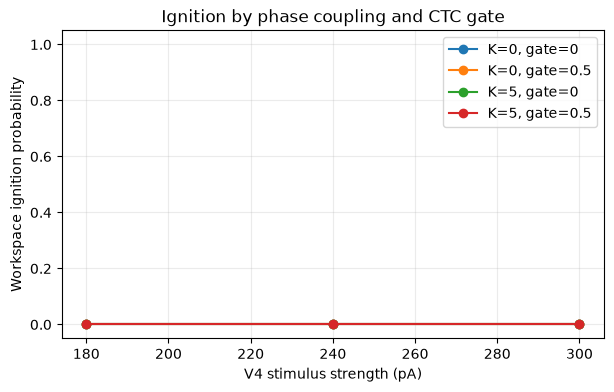

In [7]:
plt.figure(figsize=(7, 4))
for coupling_idx, coupling in enumerate(coupling_levels):
    for gate_idx, gate in enumerate(gate_levels):
        plt.plot(
            strengths_pA,
            ignition_probability[:, coupling_idx, gate_idx],
            marker="o",
            label=f"K={coupling:g}, gate={gate:g}",
        )
plt.ylim(-0.05, 1.05)
plt.xlabel("V4 stimulus strength (pA)")
plt.ylabel("Workspace ignition probability")
plt.title("Ignition by phase coupling and CTC gate")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


WARNING    C:\Windows\Temp\ipykernel_25336\2473317322.py:5: RuntimeWarning: Mean of empty slice
  mean_trace = np.nanmean(plv[strongest_idx, coupling_idx, gate_idx], axis=0)
 [py.warnings]


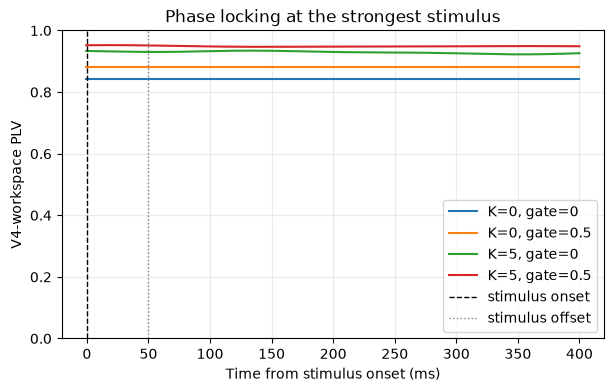

In [8]:
plt.figure(figsize=(7, 4))
strongest_idx = -1
for coupling_idx, coupling in enumerate(coupling_levels):
    for gate_idx, gate in enumerate(gate_levels):
        mean_trace = np.nanmean(plv[strongest_idx, coupling_idx, gate_idx], axis=0)
        plt.plot(time_ms, mean_trace, label=f"K={coupling:g}, gate={gate:g}")
plt.axvline(0, color="black", linewidth=1, linestyle="--", label="stimulus onset")
plt.axvline(float(network_params["stim_off"] / ms) - float(network_params["stim_on"] / ms),
            color="gray", linewidth=1, linestyle=":", label="stimulus offset")
plt.xlabel("Time from stimulus onset (ms)")
plt.ylabel("V4-workspace PLV")
plt.title("Phase locking at the strongest stimulus")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.25)
plt.show()


## Interpretation notes

This small pilot crosses stimulus strength, regional phase coupling, and phase-gate strength. The zero-coupling and zero-gate conditions are controls. Start with these three trials per condition to check that the workflow runs and the PLV responds to phase coupling. Then raise `trial_count` (for example, to 20 or more) and expand the stimulus-strength grid before estimating ignition probabilities. The 40 Hz center frequency, 2 Hz regional spread, 5 rad/s coupling, 0.5 gate, 20 Hz ignition threshold, 50 ms persistence, and 100 ms PLV window are exploratory values, not fitted biological estimates.


In [9]:
workspace_activity = firing_rates[..., workspace_indices].mean(axis=-1)
max_workspace_hz = workspace_activity.max(axis=(-1, -2))
max_workspace_hz

array([[[ 0.08859102, 13.03813805],
        [ 0.07914201,  0.08654533]],

       [[ 0.71476864,  0.31129373],
        [ 0.6801078 ,  0.27258635]],

       [[ 5.65571883, 15.62035139],
        [ 3.95832753,  0.68912737]]])

In [10]:
sensitivity_rows = []

for threshold in [5, 10, 15, 20]:
    for duration in [25, 50]:
        for strength_idx in range(len(strengths_pA)):
            for coupling_idx in range(len(coupling_levels)):
                for gate_idx in range(len(gate_levels)):
                    trial_results = []

                    for trial_idx in range(trial_count):
                        result = compute_ignition_metrics(
                            firing_rates[
                                strength_idx, coupling_idx, gate_idx, trial_idx
                            ],
                            time_ms,
                            workspace_indices,
                            threshold_hz=threshold,
                            min_duration_ms=duration,
                            onset_ms=0.0,
                        )
                        trial_results.append(result["ignited"])

                    sensitivity_rows.append({
                        "stimulus_pA": strengths_pA[strength_idx],
                        "phase_coupling_rad_s": coupling_levels[coupling_idx],
                        "phase_gate_strength": gate_levels[gate_idx],
                        "threshold_hz": threshold,
                        "min_duration_ms": duration,
                        "ignition_probability": np.mean(trial_results),
                    })

sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity

,stimulus_pA,phase_coupling_rad_s,phase_gate_strength,threshold_hz,min_duration_ms,ignition_probability
0,180.0,0.0,0.0,5,25,0.000000
1,180.0,0.0,0.5,5,25,0.333333
2,180.0,5.0,0.0,5,25,0.000000
3,180.0,5.0,0.5,5,25,0.000000
4,240.0,0.0,0.0,5,25,0.000000
...,...,...,...,...,...,...
91,240.0,5.0,0.5,20,50,0.000000
92,300.0,0.0,0.0,20,50,0.000000
93,300.0,0.0,0.5,20,50,0.000000
94,300.0,5.0,0.0,20,50,0.000000
